# 2. Preparação do Modelo Digital de Elevação (DEM)

## 2.1 Introdução

Este notebook realiza a preparação do Modelo Digital de Elevação (DEM) da Bacia Hidrográfica do Rio Doce, a partir de dados SRTM (Shuttle Radar Topography Mission) obtidos via OpenTopography. São executadas as etapas de carregamento, inspeção, padronização do sistema de referência, recorte espacial pelo limite da área de estudo, tratamento dos valores NoData, visualização e exportação do produto processado, gerando uma base topográfica padronizada para a derivação de atributos como declividade, curvaturas e direção de fluxo nas próximas etapas do projeto.

## 2.2 Objetivos

Ao final deste notebook será possível:

- carregar o Modelo Digital de Elevação (DEM) da Bacia do Rio Doce;
- verificar a consistência dos dados raster;
- converter o raster em uma matriz NumPy;
- padronizar o sistema de referência espacial entre raster e vetor;
- recortar o DEM utilizando o limite da área de estudo;
- tratar os valores NoData durante a análise e visualização, sem alterar o valor NoData do raster original;
- exportar o raster processado para utilização nas próximas etapas do projeto.

## 2.3 Bibliotecas

In [1]:
from pathlib import Path
import numpy as np
import rasterio
from rasterio.mask import mask
from rasterio.plot import show
import geopandas as gpd
import matplotlib.pyplot as plt
from rasterio.enums import Resampling

## 2.4 Estrutura dos Diretórios

In [2]:
def encontrar_raiz_projeto():
    """Localiza a raiz do projeto a partir do diretório de execução."""
    inicio = Path.cwd().resolve()

    for pasta in (inicio, *inicio.parents):
        # Critério principal: diretório Git do repositório.
        if (pasta / ".git").exists():
            return pasta

        # Alternativa para cópias do projeto sem a pasta .git.
        if (
            (pasta / "README.md").is_file()
            and (pasta / "notebooks").is_dir()
            and (pasta / "dados").is_dir()
        ):
            return pasta

    raise FileNotFoundError(
        "Não foi possível localizar a raiz do projeto. "
        "Abra o Jupyter dentro do repositório Bacia_Rio_Doce."
    )


ROOT = encontrar_raiz_projeto()

In [3]:
DIR_DADOS = ROOT / "dados"
DIR_BRUTOS = DIR_DADOS / "brutos"
DIR_PROCESSADOS = DIR_DADOS / "processados"

DIR_SRTM = DIR_BRUTOS / "SRTM"
DIR_ANA = DIR_BRUTOS / "ANA"
DIR_RELEVO = DIR_PROCESSADOS / "relevo"
DIR_AREA = DIR_PROCESSADOS / "area_estudo"

print("Estrutura de diretórios configurada.")

Estrutura de diretórios configurada.


## 2.5 Dados de entrada

Arquivo utilizados:

- bacia_rio_doce.gpkg
- dem_srtm_30m.tif

Fontes:

- Agência Nacional de Águas (ANA)
- OpenTopography DEM Downloader

Formatos:

- GeoPackage
- GeoTIFF

Sistemas de referência esperado:

- Área de estudo: EPSG:4674 (SIRGAS 2000)
- Modelo Digital de Elevação: EPSG:4326 (WGS 84)

## 2.6 Leitura

### DEM

In [4]:
INPUT_DEM = DIR_SRTM / "dem_srtm_30m.tif"

if not INPUT_DEM.is_file():
    raise FileNotFoundError(
        "O DEM de entrada não foi encontrado em: "
        f"{INPUT_DEM.relative_to(ROOT)}"
    )

In [5]:
with rasterio.open(INPUT_DEM) as dem:
    dem_crs = dem.crs
    dem_nodata = dem.nodata 
    dem_meta = dem.meta.copy()
    
    print(f"CRS: {dem.crs}")
    print(f"Formato: {dem.shape}")
    print(f"Resolução: {dem.res}")
    print(f"Limites: {dem.bounds}")
    print(f"Quantidade: {dem.count}")
    print(f"Tipo de dado: {dem.dtypes}")
    print(f"Valor NoData: {dem.nodata}")

CRS: EPSG:4326
Formato: (12324, 14899)
Resolução: (0.00027777777777781464, 0.00027777777777781464)
Limites: BoundingBox(left=-43.821249999981944, bottom=-21.182361111121885, right=-39.68263888887029, top=-17.7590277777881)
Quantidade: 1
Tipo de dado: ('float32',)
Valor NoData: -32768.0


O Modelo Digital de Elevação (DEM) representa a altitude da superfície terrestre em uma grade regular de pixels. Cada pixel armazena um valor de elevação em metros, sendo utilizado como base para o cálculo de declividade, curvaturas, direção de fluxo, acumulação de fluxo e diversas outras variáveis topográficas.

### Área de estudo

In [6]:
INPUT_AREA = DIR_AREA / "bacia_rio_doce.gpkg"

if not INPUT_AREA.is_file():
    raise FileNotFoundError(
        "O arquivo da área de estudo não foi encontrado em: "
        f"{INPUT_AREA.relative_to(ROOT)}"
    )


In [7]:
bacia_rio_doce = gpd.read_file(INPUT_AREA)

C:\Users\claud\anaconda3\envs\AmbGEO\Lib\site-packages\pyogrio\core.py:34: RuntimeWarning: Could not detect GDAL data files. Set GDAL_DATA environment variable to the correct path.
  _init_gdal_data()


In [8]:
print(f"Número de feições : {len(bacia_rio_doce)}")
print(f"CRS               : {bacia_rio_doce.crs}")
print(f"Geometria válida  : {bacia_rio_doce.is_valid.all()}")

Número de feições : 1
CRS               : EPSG:4674
Geometria válida  : True


## 2.7 Processamento

### Transformando o raster em matriz NumPy e mascarando valores NoData

In [9]:
with rasterio.open(INPUT_DEM) as dem:
    dem_np = dem.read(1, masked=True)

In [10]:
nodata = dem.nodata

total_pixels = dem_np.size
nodata_pixels = np.ma.count_masked(dem_np)
validos = total_pixels - nodata_pixels

print(f"Valor NoData: {nodata}")
print(f"Pixels totais: {total_pixels:,}")
print(f"Pixels válidos: {validos:,}")
print(f"Pixels NoData: {nodata_pixels:,}")
print(f"Tipo: {type(dem_np)}")
print(f"Formato: {dem_np.shape}")
print(f"Tipo de dado: {dem_np.dtype}")
print(f"Mínimo: {dem_np.min()}")
print(f"Máximo: {dem_np.max()}")
print(f"Média: {dem_np.mean()}")

Valor NoData: -32768.0
Pixels totais: 183,615,276
Pixels válidos: 178,754,924
Pixels NoData: 4,860,352
Tipo: <class 'numpy.ma.MaskedArray'>
Formato: (12324, 14899)
Tipo de dado: float32
Mínimo: -51.3930549621582
Máximo: 2863.340087890625
Média: 500.329379592363


### Reprojetar área de estudo

In [11]:
bacia_rio_doce = bacia_rio_doce.to_crs(dem_crs)

print(f"CRS do DEM: {dem_crs}")
print(f"CRS da área de estudo: {bacia_rio_doce.crs}")

CRS do DEM: EPSG:4326
CRS da área de estudo: GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AXIS["Latitude",NORTH],AXIS["Longitude",EAST],AUTHORITY["EPSG","4326"]]


O recorte espacial somente deve ser realizado após garantir que o raster e a camada vetorial estejam no mesmo sistema de referência. Caso contrário, as geometrias não coincidirão espacialmente, resultando em recortes incorretos ou vazios.

### Fazer recorte

In [12]:
with rasterio.open(INPUT_DEM) as dem:
    dem_recortado, transform = mask(
        dem,
        list(bacia_rio_doce.geometry),
        crop=True,
        all_touched=False  # Considera apenas os pixels cujo centro está dentro da geometria, evitando pixels que apenas tocam o limite da bacia. 
        )                  
print("DEM recortado")
print("-"*40)
print(f"Formato : {dem_recortado.shape}")
print(f"Pixels  : {dem_recortado.size:,}");

DEM recortado
----------------------------------------
Formato : (1, 12324, 14899)
Pixels  : 183,615,276


O DEM foi obtido pelo plugin OpenTopography DEM Downloader utilizando a extensão da Bacia do Rio Doce. Por isso, o raster original já possuía praticamente a mesma bounding box da área de estudo. Consequentemente, o parâmetro crop=True não reduziu o número de linhas e colunas do raster. O efeito do mask() foi transformar em NoData os pixels externos ao polígono da bacia, o que foi confirmado pela grande quantidade de pixels NoData e pela visualização do raster recortado.

### Substituir valores NoData por NAN

In [13]:
dem_plot = dem_recortado[0].copy()

dem_plot[dem_plot == dem_nodata] = np.nan

print(f"Elevação mínima : {np.nanmin(dem_plot):.2f} m")
print(f"Elevação máxima : {np.nanmax(dem_plot):.2f} m")
print(f"Elevação média  : {np.nanmean(dem_plot):.2f} m")

Elevação mínima : -41.53 m
Elevação máxima : 2631.31 m
Elevação média  : 539.73 m


A substituição dos valores NoData por NaN permite que funções do NumPy e do Matplotlib ignorem automaticamente essas regiões durante cálculos estatísticos e visualizações, evitando que valores inválidos influenciem os resultados.

## 2.8 Visualização

### Bacia sobre o DEM

C:\Users\claud\AppData\Local\Temp\ipykernel_16796\1672193376.py:4: DeprecationWarning: Setting the shape on a NumPy array has been deprecated in NumPy 2.5.
As an alternative, you can create a new view using np.reshape (with copy=False if needed).
  preview = dem.read(


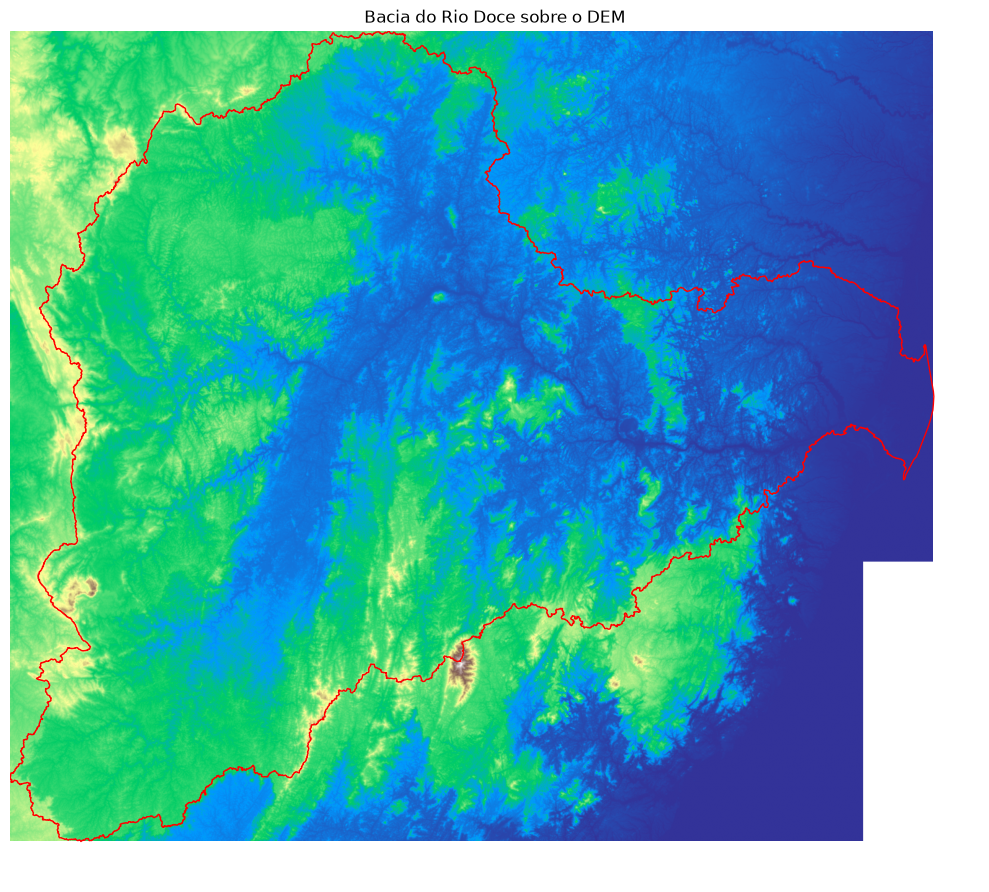

In [14]:
fator = 10   # Reduz a resolução apenas para acelerar a visualização, não alterando o raster original.

with rasterio.open(INPUT_DEM) as dem:
    preview = dem.read(
        1,
        out_shape=(dem.height // fator, dem.width // fator),
        resampling=Resampling.bilinear  # Reamostragem bilinear utilizada para gerar uma visualização em menor resolução, sem modificar o DEM original.
    )
    preview[preview == dem_nodata] = np.nan
    preview_transform = dem.transform * dem.transform.scale(fator, fator)

fig, ax = plt.subplots(figsize=(10, 10))

show(preview, transform=preview_transform, ax=ax, cmap="terrain")

bacia_rio_doce.boundary.plot(
    ax=ax,
    color="red",
    linewidth=1
)

ax.set_title("Bacia do Rio Doce sobre o DEM")
ax.set_axis_off()
plt.tight_layout()
plt.show()

### Bacia Recortada

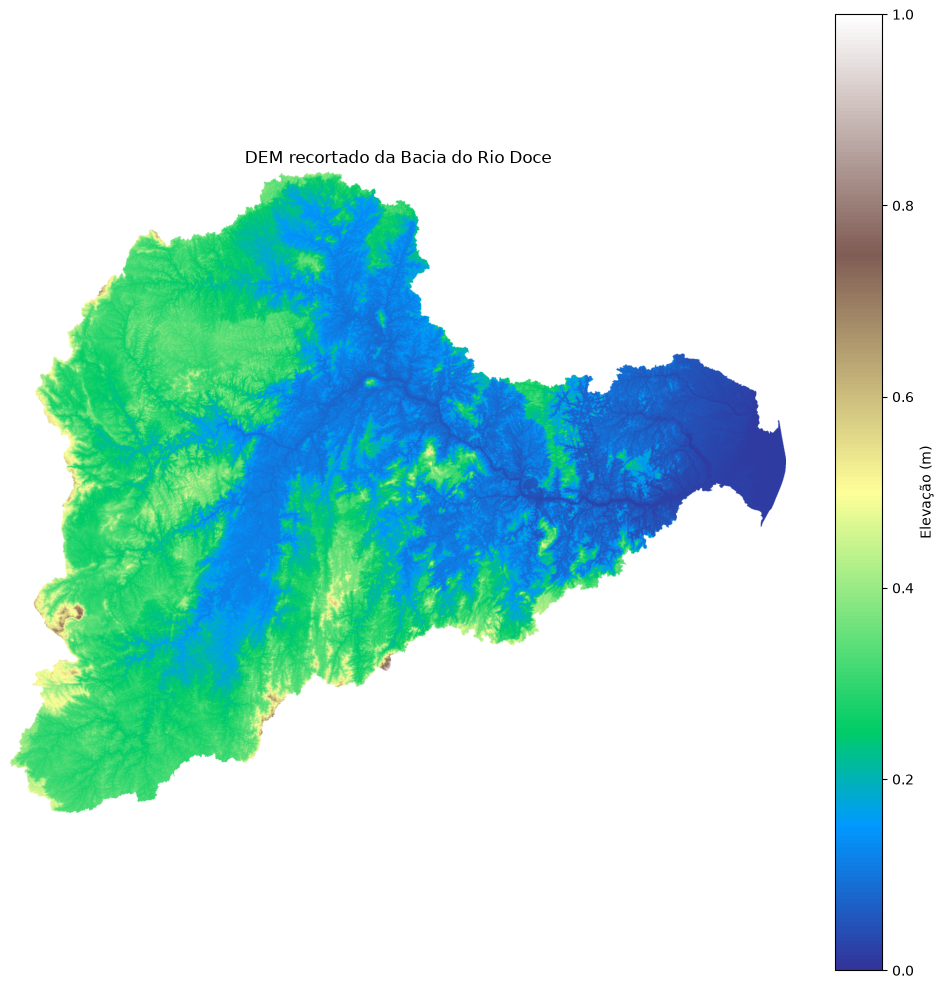

In [15]:
fator = 5   # Reduz a quantidade de pixels exibidos apenas para melhorar o desempenho da visualização.

dem_plot_preview = dem_plot[::fator, ::fator]
transform_preview = transform * transform.scale(fator, fator)

fig, ax = plt.subplots(figsize=(10, 10))

show(dem_plot_preview, transform=transform_preview, ax=ax, cmap="terrain")
plt.colorbar(ax.images[0], ax=ax, label="Elevação (m)")

ax.set_title("DEM recortado da Bacia do Rio Doce")
ax.set_axis_off()
plt.tight_layout()
plt.show()

## 2.9 Exportação

In [16]:
OUTPUT_DEM = DIR_RELEVO / "dem_rio_doce.tif"

### Atualizar metadados

In [17]:
out_meta = dem_meta.copy()

out_meta.update({
    "driver": "GTiff",
    "height": dem_recortado.shape[1],
    "width": dem_recortado.shape[2],
    "transform": transform,
    "compress": "deflate",
    "predictor": 3,  
    "tiled": True,
    "blockxsize": 256,
    "blockysize": 256,
})

In [18]:
print("Metadados do raster de saída:")
print(f"Driver: {out_meta['driver']}")
print(f"CRS: {out_meta['crs']}")
print(f"Dimensões: {out_meta['height']} x {out_meta['width']}")
print(f"Resolução: {out_meta['transform'].a}, {abs(out_meta['transform'].e)}")
print(f"NoData: {out_meta['nodata']}")
print(f"Tipo: {out_meta['dtype']}")
print(f"Bandas: {out_meta['count']}")

Metadados do raster de saída:
Driver: GTiff
CRS: EPSG:4326
Dimensões: 12324 x 14899
Resolução: 0.00027777777777781464, 0.00027777777777781464
NoData: -32768.0
Tipo: float32
Bandas: 1


A atualização dos metadados garante que o raster exportado mantenha corretamente sua posição geográfica, dimensões, sistema de referência e resolução espacial, permitindo sua utilização em softwares SIG como QGIS e ArcGIS.

## 2.10 Salvar o raster processado

In [19]:
OUTPUT_DEM.parent.mkdir(parents=True, exist_ok=True)

with rasterio.open(OUTPUT_DEM, "w", **out_meta) as dest:
    dest.write(dem_recortado)

print(
    "Arquivo salvo com sucesso em: "
    f"{OUTPUT_DEM.relative_to(ROOT)}"
)

Arquivo salvo com sucesso em: dados\processados\relevo\dem_rio_doce.tif


### Verificar o arquivo gerado

In [20]:
with rasterio.open(OUTPUT_DEM) as dem_ds:
    print("CRS:", dem_ds.crs)
    print("Dimensões:", dem_ds.height, "x", dem_ds.width)
    print("Resolução:", dem_ds.res)
    print("Bounds:", dem_ds.bounds)
    print("NoData:", dem_ds.nodata)

CRS: EPSG:4326
Dimensões: 12324 x 14899
Resolução: (0.00027777777777781464, 0.00027777777777781464)
Bounds: BoundingBox(left=-43.821249999981944, bottom=-21.182361111121885, right=-39.68263888887029, top=-17.7590277777881)
NoData: -32768.0


### Liberação da memória

In [21]:
del dem_np, dem_recortado, dem_plot
import gc
gc.collect()

3104

## 2.11 Conclusão

Neste notebook foi preparado o Modelo Digital de Elevação da Bacia do Rio Doce. O raster original — obtido via OpenTopography a partir de dados SRTM — foi carregado, inspecionado, recortado utilizando o limite da área de estudo, teve seus valores NoData tratados e foi exportado em formato GeoTIFF comprimido, preservando todos os metadados espaciais necessários para as próximas etapas do projeto. O arquivo exportado foi verificado e a memória utilizada pelas matrizes intermediárias foi liberada ao final do processamento. Diferentemente do notebook de preparação do MapBiomas, a obtenção do DEM ainda depende de uma etapa manual externa ao código (download via plugin OpenTopography, documentado na seção 2.5); automatizar esse download por meio da API do OpenTopography é uma melhoria futura possível para tornar o notebook totalmente reprodutível de ponta a ponta. Este produto será utilizado como base para a derivação dos atributos topográficos, como declividade, curvaturas e índices hidrológicos.